In [1]:
import torch
import torch.nn                         as nn
import torch.optim                      as optim
import pacmap
import umap.umap_                       as umap 
import numpy                            as np
import pandas                           as pd

from sklearn.decomposition              import PCA
import seaborn                          as sns
import matplotlib.pyplot                as plt
import matplotlib.gridspec              as gridspec
import plotly.express                   as px
import plotly.graph_objects             as go

from tqdm                               import tqdm
from plotly.subplots                    import make_subplots
from sklearn.preprocessing              import StandardScaler, MinMaxScaler
from sklearn.cluster                    import DBSCAN, KMeans 
from sklearn.mixture                    import GaussianMixture
from sklearn.model_selection            import train_test_split
from transformers                       import BertTokenizer, BertForSequenceClassification, GPT2Model, GPT2Tokenizer, GPT2ForSequenceClassification
from torch.utils.data                   import DataLoader, Dataset


from utils.Preprocessing2               import PreProcessData
from utils.plotFigures                  import lineAndScatterPlot, linePlot, scatterPlot2D, plot_learning_curves
from clustering.plotClustering          import ClusteringResults
#from model.CustomDataset                import BertDataset, TextDataset, GPTDataset
from model.trainFunctions               import train_classification_model

# Work in progress

# Preprocessing

In [2]:
preData = PreProcessData()
df, scaled_data = preData.preprocessing(type_file = 'h5', scaler = MinMaxScaler(), window_size = 6, time_aggregation='10min', threshold=200)

In [ ]:
# df_info = []
# for i in range(4):
#     df_i, scaled_data_i = preData.preprocessing(type_file = 'h5', scaler = MinMaxScaler(), window_size = 6*2**i, aggregation='10min', threshold=200)
#     df_info.append(df_i)

In [3]:
# variable = preData.new_efficiency_cr1[0]
# i = 2
# lineAndScatterPlot(df_info[i][df_info[i]['tiempo'].between('2023-01-01 00:00:00', '2023-01-10 00:00:00')], x='tiempo', y=variable, color=f'{variable}_description')

In [ ]:
def lineAndScatterPlot(data, x, y, color, title='Time series'):
    data        = data.copy()
    #data[color] = data[color].astype('str')
    fig = px.scatter(data, 
                     x      = x, 
                     y      = y, 
                     color  = color)
    
    line_plot = px.line(data, 
                        x   = x, 
                        y   = y)

    fig.update_layout(title=title,
        template='plotly_white',
        plot_bgcolor='rgba(255, 255, 255, 1)',
        paper_bgcolor='rgba(255, 255, 255, 1)',
        xaxis=dict(showgrid=False, zeroline=False, showline=True, linecolor='black'),
        yaxis=dict(showgrid=False, zeroline=False, showline=True, linecolor='black'),
        width=900, 
        height=350  
    )
    fig.add_trace(line_plot.data[0])
    fig.update_traces(line=dict(color='black'))
    fig.show()

# Manipulable

In [8]:
df_manipulable = scaled_data[preData.manipulated_cr1+preData.new_manipulable_cr1]

clusteringModels    = {
    'pca': KMeans(n_clusters=2),
    #'umap':  KMeans(n_clusters=2),
    'pacmap': GaussianMixture(n_components=3, random_state=2, n_init=5)} 

dimReductionModels  = {
    'pca': PCA(n_components = 2),
    #'umap': umap.UMAP(n_components = 2, random_state = 40),
    'pacmap': pacmap.PaCMAP(n_components = 2, random_state = 40, save_tree    = True)}

Manipulable = ClusteringResults(data                = scaled_data, 
                                dataNormalized      = df_manipulable, 
                                clusteringModels    = clusteringModels, 
                                dimReductionModels  = dimReductionModels)

# Train dimensionality reduction model
Manipulable.train()
Manipulable.getResults2()

for traj in tqdm(Manipulable.trajectories):
    Manipulable.clustersResults[traj] = Manipulable.embedding[Manipulable.data['trajectory'] == traj]

c:\Users\CAEX\Desktop\Diego\Crusher Project\2ndrealdatajournalchile\mmodal\Lib\site-packages\pacmap\pacmap.py:828: UserWarning:


100%|██████████| 24/24 [00:00<00:00, 685.10it/s]


<Axes: >

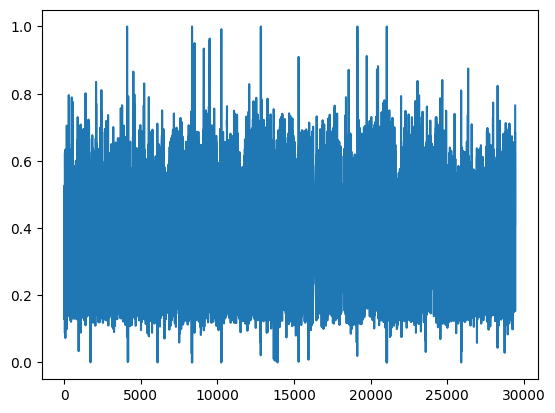

In [71]:
data = Manipulable.embedding
data[preData.manipulated_cr1[0]].plot() # [data[preData.new_manipulable_cr1[2]]>0.7][preData.new_manipulable_cr1[2]].plot()

In [68]:
algorithm='pacmap'
scatterPlot2D(Manipulable.embedding, #[Manipulable.embedding[preData.manipulated_cr1[2]]>0.75], 
              x=f'{algorithm}_x', y=f'{algorithm}_y', color=preData.manipulated_cr1[2])

In [5]:
variable = preData.new_manipulable_cr1[1]
i = 2
lineAndScatterPlot(Manipulable.embedding[Manipulable.embedding['tiempo'].between('2023-01-01 00:00:00', '2023-01-10 00:00:00')], x='tiempo', y=variable, color='cluster_pacmap')

# Efficiency

In [ ]:
columns         = preData.efficiency_cr1+preData.new_efficiency_cr1
df_efficiency   = scaled_data[columns]


clusteringModels    = {
    #'pca': KMeans(n_clusters=2),
    #'umap':  KMeans(n_clusters=2),
    'pacmap': GaussianMixture(n_components=5, random_state=3, n_init=5)
    } 

dimReductionModels  = {
    #'pca': PCA(n_components = 2),
    #'umap': umap.UMAP(n_components = 2, random_state = 40),
    'pacmap': pacmap.PaCMAP(n_components = 3, random_state = 40, save_tree    = True)}


Efficiency = ClusteringResults(data                = scaled_data, 
                               dataNormalized      = df_efficiency, 
                               clusteringModels    = clusteringModels, 
                               dimReductionModels  = dimReductionModels)

Efficiency.train()
Efficiency.getResults2()

for traj in tqdm(Efficiency.trajectories):
    Efficiency.clustersResults[traj] = Efficiency.embedding[Efficiency.data['trajectory'] == traj]

In [ ]:
scatterplot2D_colored(Manipulable.embedding[Manipulable.embedding['trajectory']=='25'],
                      color= 'cluster_pacmap', #preData.new_efficiency_cr1[2],
                      algorithm='pacmap',
                      title='Campaña 25')

In [ ]:
stop

In [ ]:
scatterplot3D_colored(Manipulable.embedding[Manipulable.embedding[preData.new_manipulable_cr1[2]]>0.7],
                      color=preData.new_manipulable_cr1[2],
                      algorithm='pacmap')

In [ ]:
#scatterPlot2D(Manipulable.embedding, x='pacmap_x', y='pacmap_y', color='cluster_pacmap')
scatterplot2D_colored(Manipulable.embedding[(Manipulable.embedding[preData.manipulated_cr1[6]]<0.4)&
                                            Manipulable.embedding[preData.manipulated_cr1[6]]>0.1], 
                      variable=preData.manipulated_cr1[6],
                      algorithm='pca'
                      )

In [ ]:
stop

In [ ]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram
def order_matrix(matrix):

    # Se crea el objeto de clustering jerárquico con single linkage. Nos interesa el dendrograma más que los clusters.
    clust = AgglomerativeClustering(linkage = "single", compute_full_tree = True,
                                    distance_threshold =0, n_clusters=None)
    clust.fit(matrix)

    # Creamos el objeto necesario para la creación del dendrograma. Sólo children es realmente útil
    linkage_matrix = np.column_stack([clust.children_, clust.distances_,
                                      np.zeros(clust.children_.shape[0])]).astype(float)

    # Creamos el dendrograma, del cual nos interesa el objeto "leaves" que contiene el órden.
    order = dendrogram(linkage_matrix, no_plot=True)["leaves"]

    return order

columns=preData.efficiency_cr1+preData.new_efficiency_cr1
#columns=preData.manipulated_cr1+preData.new_manipulable_cr1
correlacion = scaled_data[columns].corr()
order = order_matrix(correlacion)

In [ ]:
from colorsys import hsv_to_rgb
def plot_loadings(model, unitary=False):
    fig, ax = plt.subplots(figsize = (7,7))
    loadings = model.components_.T
    loadings = loadings if unitary else (loadings * np.sqrt(model.explained_variance_))

    ax.scatter(*(Efficiency.embedding[['pca_x', 'pca_y']].values).T, marker='.', color='bisque')

    np.random.seed(3)
    for name, vector in zip(model.feature_names_in_, loadings):
        color = hsv_to_rgb(*np.random.uniform(size = 3) * [1, 0.5, 0.6] + [0,0.5, 0.3])
        ax.arrow(0, 0, vector[0]*6, vector[1]*6, head_length=0.2, head_width=0.2,
                  width=0.001, color=color)
        ax.text(*(vector*5 +np.sign(vector)*[0.9,0.7]), name, ha = 'center', va = 'center', color=color)
    ax.set_xlim(-6, 7)
    ax.set_ylim(-5,5)
    ax.set_xlabel("Componente Principal 1")
    ax.set_ylabel("Componente Principal 2")
    return fig

fig = plot_loadings(Efficiency.dimReductionModels['pca'])
fig.show()

In [ ]:
stop

In [ ]:
data = Efficiency.embedding.copy()
data.rename(columns={'cluster_pacmap': 'cluster'}, inplace=True)
fig = px.scatter(data, x='tiempo', y=preData.new_efficiency_cr1[2], color='cluster')

fig.update_layout(
    template='plotly_white',
    plot_bgcolor='rgba(255, 255, 255, 1)',
    paper_bgcolor='rgba(255, 255, 255, 1)',
    xaxis=dict(showgrid=False, zeroline=False, showline=True, linecolor='black'),
    yaxis=dict(showgrid=False, zeroline=False, showline=True, linecolor='black'),
    height=300,
    width=700
)
fig.show()

# Holdout

In [ ]:
df.loc[:, 'manipulable_cluster_pacmap'] = Manipulable.embedding['cluster_pacmap']
df.loc[:, 'efficieny_cluster_pacmap']  = Efficiency.embedding['cluster_pacmap']

In [ ]:
df.loc[:, 'text'] = df['manipulable_cluster_pacmap'].replace({'0': 'A', '1': 'B', '2':'C'})

In [ ]:
X = df[['text']]
y = df['efficieny_cluster_pacmap'].astype('int')

#Aplicar el undersampling
rus = RandomUnderSampler(random_state=42)
X_res, y_res = rus.fit_resample(X, y)

X_train, X_temp, y_train, y_temp = train_test_split(X_res.sort_index(), y_res.sort_index(), test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

In [ ]:
px.scatter(Efficiency.embedding[Efficiency.embedding.index.isin(y_res.index)], x='tiempo', y=preData.efficiency_cr1[0], color='cluster_pacmap')

In [ ]:
# df_text = pd.DataFrame({})

# for i, data in enumerate(df_info):
#     df_text.loc[:, f'Lubricación_depósito(%)_description_{2**i}_hr'] = data['Lubricación_depósito(%)_description']
#     df_text.loc[:, f'Discrepancia_Voltaje_Motor_description_{2**i}_hr'] = data['Discrepancia_Voltaje_Motor_description']


In [ ]:
#df['text'] = df_text.apply(lambda row: " [SEP] ".join(row.to_list()) + " [SEP]", axis=1)

In [ ]:
df_ = df[df['tiempo'].between('2023-03-10 18:00:00', '2023-03-11 10:00:00')].copy()
df_['efficieny_cluster_pacmap'] = df_['efficieny_cluster_pacmap'].astype('str')

fig = px.scatter(df_, x='tiempo', y=[0]*len(df_), color="text",  text='text')

fig.update_layout(
        template='plotly_white',
        plot_bgcolor='rgba(255, 255, 255, 1)',
        paper_bgcolor='rgba(255, 255, 255, 1)',
        xaxis=dict(showgrid=False, zeroline=False, showline=True, linecolor='black'),
        yaxis=dict(showgrid=False, zeroline=False, showline=True, linecolor='black'),
        height=200
    )
fig.for_each_trace(lambda t: t.update(textfont_color=t.marker.color, textposition='top center'))
fig.show()


In [ ]:
# df['id_text'] = (df['text'] != df['text'].shift()).cumsum()
# df.groupby('id_text').size().describe()

In [ ]:
stop

# Dataloader

In [ ]:
class BERTDataset(Dataset):
    def __init__(self, data, texts, labels, tokenizer, window_size, max_len):
        self.data               = data
        self.texts              = texts
        self.labels             = labels
        self.tokenizer          = tokenizer
        self.max_len            = max_len
        self.window_size        = window_size
        self.pretokenized_texts = self.pretokenize_texts()

    def pretokenize_texts(self):
        pretokenized_text   = []
        for index in self.texts.index:
            context_window           = self.data[['text']].loc[index-self.window_size:index].T
            add_especial_tokens      = context_window.apply(lambda row: "[CLS] " + " [SEP] ".join(row.to_list()) + " [SEP]", axis=1).item()
            pretokenized_text.append(add_especial_tokens)
        return pretokenized_text

    def __len__(self):
        return len(self.pretokenized_texts)

    def __getitem__(self, idx):
        text        = self.pretokenized_texts[idx]
        label       = self.labels[idx]
        encoding    = self.tokenizer.encode_plus(
            text                    = text,
            truncation              = True,
            add_special_tokens      = False,
            max_length              = self.max_len,
            return_token_type_ids   = False,
            padding                 = 'max_length',
            return_attention_mask   = True,
            return_tensors          = 'pt',
        )
        
        return {
            'text':             text,
            'input_ids':        encoding['input_ids'].flatten(),
            'attention_mask':   encoding['attention_mask'].flatten(),
            'labels':           torch.tensor(label, dtype=torch.long)
        }

In [ ]:
MAX_LEN     = 200
BATCH_SIZE  = 64
WINDOW_SIZE = 200
model_name  = "huawei-noah/TinyBERT_General_4L_312D" #'bert-base-uncased'
tokenizer   = BertTokenizer.from_pretrained(model_name)

train_dataset = BERTDataset(
    data        = df[['text']],
    texts       = X_train[['text']],
    labels      = y_train.tolist(),
    tokenizer   = tokenizer,
    window_size = WINDOW_SIZE, 
    max_len     = MAX_LEN
)

val_dataset = BERTDataset(
    data        = df[['text']],
    texts       = X_val[['text']],
    labels      = y_val.tolist(),
    tokenizer   = tokenizer,
    window_size = WINDOW_SIZE, 
    max_len     = MAX_LEN
)

test_dataset = BERTDataset(
    data        = df[['text']],
    texts       = X_test[['text']],
    labels      = y_test.tolist(),
    tokenizer   = tokenizer,
    window_size = WINDOW_SIZE, 
    max_len     = MAX_LEN
)

train_loader    = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader      = DataLoader(val_dataset,   batch_size=BATCH_SIZE)
test_loader     = DataLoader(test_dataset,  batch_size=BATCH_SIZE)

In [ ]:
class GPTDataset(Dataset):
    def __init__(self, data, texts, labels, tokenizer, window_size, max_len):
        self.data               = data
        self.texts              = texts
        self.labels             = labels
        self.tokenizer          = tokenizer
        self.max_len            = max_len
        self.window_size        = window_size
        self.pretokenized_texts = self.pretokenize_texts()

    def pretokenize_texts(self):
        pretokenized_text   = []
        for index in self.texts.index:
            context_window           = self.data[['text']].loc[index-self.window_size:index].T
            add_especial_tokens      = context_window.apply(lambda row: " ".join(row.to_list()), axis=1).item()
            pretokenized_text.append(add_especial_tokens)
        return pretokenized_text

    def __len__(self):
        return len(self.pretokenized_texts)

    def __getitem__(self, idx):
        text        = self.pretokenized_texts[idx]
        label       = self.labels[idx]
        encoding    = self.tokenizer.encode_plus(
            text                    = text,
            truncation              = True,
            add_special_tokens      = False,
            max_length              = self.max_len,
            return_token_type_ids   = False,
            padding                 = 'max_length',
            return_attention_mask   = True,
            return_tensors          = 'pt',
        )
        
        return {
            'text':             text,
            'input_ids':        encoding['input_ids'].flatten(),
            'attention_mask':   encoding['attention_mask'].flatten(),
            'labels':           torch.tensor(label, dtype=torch.long)
            }

In [ ]:
MAX_LEN     = 200
BATCH_SIZE  = 64
WINDOW_SIZE = 200
model_name  = 'gpt2'
tokenizer   = GPT2Tokenizer.from_pretrained(model_name)
tokenizer.padding_side = "left"
tokenizer.pad_token = tokenizer.eos_token

train_dataset = GPTDataset(
    data        = df[['text']],
    texts       = X_train[['text']],
    labels      = y_train.tolist(),
    tokenizer   = tokenizer,
    window_size = WINDOW_SIZE, 
    max_len     = MAX_LEN
)

val_dataset = GPTDataset(
    data        = df[['text']],
    texts       = X_val[['text']],
    labels      = y_val.tolist(),
    tokenizer   = tokenizer,
    window_size = WINDOW_SIZE, 
    max_len     = MAX_LEN
)

test_dataset = GPTDataset(
    data        = df[['text']],
    texts       = X_test[['text']],
    labels      = y_test.tolist(),
    tokenizer   = tokenizer,
    window_size = WINDOW_SIZE, 
    max_len     = MAX_LEN
)

train_loader    = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader      = DataLoader(val_dataset,   batch_size=BATCH_SIZE)
test_loader     = DataLoader(test_dataset,  batch_size=BATCH_SIZE)

In [ ]:
B = next(iter(train_loader))
B['input_ids'].shape

# Training Model

In [ ]:
class SimpleGPT2SequenceClassifier(nn.Module):
    def __init__(self, hidden_size: int, num_classes:int ,max_seq_len:int, gpt_model_name:str):
        super(SimpleGPT2SequenceClassifier,self).__init__()
        self.gpt2model = GPT2Model.from_pretrained(gpt_model_name)
        self.fc1 = nn.Linear(hidden_size*max_seq_len, num_classes)


    def forward(self, input_ids, attention_mask):
        """
        Args:
                input_ids: encoded inputs ids of sent.
        """
        gpt_out, _ = self.gpt2model(input_ids=input_ids, attention_mask=attention_mask, return_dict=False)
        batch_size = gpt_out.shape[0]
        linear_output = self.fc1(gpt_out.view(batch_size,-1))
        return linear_output

In [ ]:
model = SimpleGPT2SequenceClassifier(hidden_size=768, num_classes=len(y_train.unique()), max_seq_len=200, gpt_model_name="gpt2")
model = model.to('cuda')

for param in model.gpt2model.parameters():
    param.requires_grad = False

In [ ]:
model       = BertForSequenceClassification.from_pretrained(model_name, num_labels=len(y_train.unique()))
model = model.to('cuda')

#Freezing
for param in model.bert.parameters():
    param.requires_grad = False

In [ ]:
parameters=filter(lambda p: p.requires_grad, model.parameters())
num_params_model = sum([np.prod(p.size()) for p in parameters])
num_params_model

In [ ]:
optimizer   = optim.AdamW(model.parameters(), lr=0.001)
EPOCHS      = 2

train_acc_curve, val_acc_curve, train_loss_curve, val_loss_curve = train_classification_model(model             = model, 
                                                                                              optimizer         = optimizer, 
                                                                                              train_iterator    = train_loader, 
                                                                                              valid_iterator    = val_loader,
                                                                                              test_iterator     = test_loader, 
                                                                                              epochs            = EPOCHS,
                                                                                              dir_model         = 'saved_models/gpt2_17_07.pt')
# Learning curves
#plot_learning_curves(train_acc_curve, val_acc_curve, train_loss_curve, val_loss_curve)

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

device = 'cuda'
# Cambia el modelo a modo de evaluación
model.eval()

# Lista para almacenar las predicciones y etiquetas reales
all_predictions = []
all_labels = []

# Desactiva el cálculo de gradientes
with torch.no_grad():
    for batch in test_loader:
        input_ids       = batch['input_ids'].to(device)
        attention_mask  = batch['attention_mask'].to(device)
        labels          = batch['labels'].to(device)
        outputs = model(input_ids=input_ids, attention_mask=attention_mask).logits
        
        # Aplica softmax para convertir los logits en probabilidades
        probabilities = torch.softmax(outputs, dim=1)
        
        # Obtén las predicciones (la clase con mayor probabilidad)
        _, predicted = torch.max(probabilities, 1)
        
        # Almacena las predicciones y las etiquetas reales
        all_predictions.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

In [ ]:
# Calcula la matriz de confusión
cm = confusion_matrix(all_labels, all_predictions)

# Configuración para la visualización
plt.figure(figsize=(6, 4))
sns.set(font_scale=1.4)  # Para aumentar el tamaño de la fuente en la gráfica

# Graficar la matriz de confusión
sns.heatmap(cm, annot=True, annot_kws={"size": 12}, cmap='Blues', fmt='g')
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Matriz de confusión')

# Mostrar la gráfica
plt.show()

In [ ]:
y_res.value_counts()

# ----

In [ ]:
stop

In [ ]:
import plotly.colors as colors

In [ ]:
fig = go.Figure()
cmap = colors.sequential.Turbo #['#440154', '#3B528B', '#21918C', '#5DC863', '#FDE725']
for i, df_ in enumerate(df_info):
    df_ = df_[df_['tiempo'].between('2023-07-12 00:00:00', '2023-07-14 00:00:00')]
    fig.add_trace(go.Scatter(
        x=df_['tiempo'],
        y=df_[f'{variable}_derivative_sum'],
        mode='lines',
        name=f'Suma móvil con una ventana de {2**i} hrs',
        #line=dict(color=cmap[0])
    ))

fig.update_layout(
    title=f'Comparación de la suma móvil de la tasa de cambio de {variable}',
    xaxis_title='tiempo',
    yaxis_title='Suma de la derivada',
    legend_title=None,
    template='plotly_white',
    plot_bgcolor='rgba(255, 255, 255, 1)',
    paper_bgcolor='rgba(255, 255, 255, 1)',
    xaxis=dict(showgrid=False, zeroline=False, showline=True, linecolor='black'),
    yaxis=dict(showgrid=False, zeroline=False, showline=True, linecolor='black'),
    width=900, 
    height=350  
)

fig.show()

In [ ]:
variable = preData.new_manipulable_cr1[1]

for i, df_ in enumerate(df_info):
    df_ = df_[df_['tiempo'].between('2023-07-12 00:00:00', '2023-07-14 00:00:00')]
    plt.plot(df_['tiempo'], df_[f'{variable}_derivative_sum'], label=f'suma derivada con {2**i} hrs')
plt.legend()

In [ ]:
variable = preData.new_manipulable_cr1[1]

for i in range(3):
    window_size = 2**i
    df_ = df[df['tiempo'].between('2023-07-12 00:00:00', '2023-07-14 00:00:00')]
    derivative      = df_[variable].rolling(window=window_size, min_periods=1, center=True).mean().diff().copy()
    derivative_sum  = derivative.rolling(window=window_size, min_periods=1).sum()
    derivative_sign = np.sign(derivative.rolling(window=window_size, min_periods=1, center=True).median())


    #plt.plot(df_['tiempo'], df_[variable], label=f'{variable}')
    #plt.plot(df_['tiempo'], derivative, label='derivada')
    plt.plot(df_['tiempo'], derivative_sum, label=f'suma derivada con {2**i} hrs')
plt.legend()

In [ ]:
plt.plot(df_['tiempo'], df_[variable], label=f'{variable}')
plt.plot(df_['tiempo'], derivative, label='derivada')
plt.plot(df_['tiempo'], derivative_sum, label='suma de derivada')
plt.legend(loc='upper left')

In [ ]:
plt.scatter(df_['tiempo'],derivative_sign, marker='.')

In [ ]:
df_[preData.new_manipulable_cr1[1]].plot()

In [ ]:
derivative_sign.plot()
